## Applying effect size criterion

In the main analysis we find the dimensionality by applying only the signifficance criterion using cblearn.
Here we apply the effect size criterion for different minimal effect size, systematically varying it.

- On the one extreme, 0% returns us to the signifficance criterion only.
- On the other extreme, a high % will make a dimension higher than 1 unlikely / impossible to be achieved, thus for all cases
dimensionality should collapse to 1 with a high %.

Here we vary systematically this delta %  criterion and see the effect on dimensionality. 

For a particular value, 2 %, we save updated stats (json files), as an example of possible fixed value.

In [1]:
import pandas as pd
import numpy as np
import json
import ast
import seaborn as sns
import matplotlib

import cblearn


from io_json import read_json_dataclass, save_json_dict
from sdt_utils_and_logodds import recalculate_dimensionality
from dimensionality_estimation import fit_embedding

# Arial and a light grey frame as in the other figures of the paper, without grid
sns.set_style('whitegrid', {'axes.grid': False})
# the Delta of the axis label in Arial too, instead of the default math font
matplotlib.rcParams['mathtext.fontset'] = 'custom'
matplotlib.rcParams['mathtext.rm'] = 'Arial'
matplotlib.rcParams['mathtext.it'] = 'Arial:italic'
sns.set_context('notebook')  # as the other figures of the paper

palette_imset = {'action': (0.4, 0.7607843137254902, 0.6470588235294118),
                 'greebles': (0.9882352941176471, 0.5529411764705883, 0.3843137254901961),
                 'taxonomic': (0.5529411764705883, 0.6274509803921569, 0.796078431372549),
                }     

palette_task = sns.mpl_palette("viridis", 2)

PARTICULAR_DELTA = 0.02  # 2 %

# seeds the SOE initialisation of the refitted embeddings
SEED = 0

## Recalculating dimensionality for all data as a function of delta % criterion

In [2]:
obss = 'all'

# read data 
df = pd.read_csv('../data/found-dimensionality-embeddings-aggregated-per-observer-nsplit-5-nrepeat-30.csv')

if obss == 'O1-O5':
    df = df[(df['observer']=='O1') | (df['observer']=='O2') | (df['observer']=='O3') |
        (df['observer']=='O4') | (df['observer']=='O5')]
elif obss == 'P1-P2':
    df = df[(df['observer']=='P1') | (df['observer']=='P2')]

In [3]:
# read data pooled O1 - O5
df_pooled = pd.read_csv('../data/found-dimensionality-embeddings-pooled-observers-nsplit-5-nrepeat-30.csv')

df = pd.concat((df, df_pooled))

In [4]:
df['triplets'] = df['triplets'].apply(lambda x: np.array(ast.literal_eval(x)))

In [5]:
deltas = np.arange(0, 0.14, 0.001)
debug = False

In [6]:
df.columns

Index(['observer', 'task', 'image_set', 'embedding_ready_triplets',
       'raw_triplets', 'responses', 'Nt', 'dimensionality', 'embedding',
       'triplets'],
      dtype='object')

In [7]:
print('re-estimating dimensionality...')

data = []
new_data = []
for ix, d in df.iterrows():

    # unpacking values
    obs = d['observer']
    task = d['task']
    image_set = d['image_set']
    embedding_ready_triplets = d['embedding_ready_triplets']
    Nt = d['Nt']    
    triplets = d['triplets']
    embedding = d['embedding']
    dimensionality = d['dimensionality']

    
    # read dim_result from JSON, this is the dataclass returned by cblearn
    dim_result = read_json_dataclass(f"../data/triplet_accuracy_vs_dimensionality-{obs}-{task}-{image_set}.json")
    dim1 = dim_result.estimated_dimension
    print(f"{obs} - {task} - {image_set}")
    if debug:
        print(f"1. signifficance criterion: {dim1}  dimension(s)")   
    
    # we now recalculate the dimensionalty by including the effect size criterion
    # for varying levels of effect size
    if debug:
        print('2. effect size criterion:')
        print('delta | dimension(s)')

    # the dimensionality under the effect-size criterion at PARTICULAR_DELTA, written to the -LogOdds tables
    dim_particular = None
    for delta in deltas:
        dim_result_corrected = recalculate_dimensionality(dim_result, criterion='LogOdds', p=0.75, delta=delta)
        dim2 = dim_result_corrected['estimated_dimension']
        dim_result_corrected['estimated_dimension'] = np.array(dim_result_corrected['estimated_dimension'])

        if delta == PARTICULAR_DELTA:
            dim_particular = dim2
            if dim1 != dim2:
                # we need to rerun and save
                print(f"re-estimating embedding {dim1} -> {dim2}")
                embedding = fit_embedding(triplets, dim2, random_state=SEED).tolist()
        
            # saving corrected dictionary
            save_json_dict(dim_result_corrected, f"../data/triplet_accuracy_vs_dimensionality-{obs}-{task}-{image_set}_LogOdds.json")
            
        if debug:
            print(f" {int(delta*100):2d} % | {dim2}")

        data.append([obs, image_set, task, delta, dim2])
    # the embedding is text from the csv, or a list when it was refitted above
    embedding_shape = np.array(ast.literal_eval(embedding) if isinstance(embedding, str) else embedding).shape
    assert dim_particular is not None and embedding_shape[1] == dim_particular
    new_data.append([obs, task, image_set, embedding_ready_triplets, Nt, dim_particular, embedding, triplets])

df_criteria = pd.DataFrame(data, columns=['obs', 'image_set', 'task', 'delta', 'dim'])

new_df = pd.DataFrame(new_data, columns=['observer', 'task', 'image_set', 'embedding_ready_triplets', 'Nt', 'dimensionality', 'embedding', 'triplets'])

re-estimating dimensionality...
O1 - classic - action
O1 - classic - greebles
O1 - classic - taxonomic
O1 - odd one out - action
O1 - odd one out - greebles
O1 - odd one out - taxonomic
O1 - odd-one-out-oneoftwo - action
O1 - odd-one-out-oneoftwo - greebles
O1 - odd-one-out-oneoftwo - taxonomic
O2 - classic - action
O2 - classic - greebles
O2 - classic - taxonomic
O2 - odd one out - action
O2 - odd one out - greebles
O2 - odd one out - taxonomic
O2 - odd-one-out-oneoftwo - action
O2 - odd-one-out-oneoftwo - greebles
O2 - odd-one-out-oneoftwo - taxonomic
O3 - classic - action
O3 - classic - greebles
O3 - classic - taxonomic
O3 - odd one out - action
re-estimating embedding 3 -> 2


O3 - odd one out - greebles
O3 - odd one out - taxonomic
O3 - odd-one-out-oneoftwo - action
re-estimating embedding 4 -> 3


O3 - odd-one-out-oneoftwo - greebles
O3 - odd-one-out-oneoftwo - taxonomic
O4 - classic - action
O4 - classic - greebles
O4 - classic - taxonomic
O4 - odd one out - action
O4 - odd one out - greebles
re-estimating embedding 2 -> 1


O4 - odd one out - taxonomic
O4 - odd-one-out-oneoftwo - action
O4 - odd-one-out-oneoftwo - greebles
O4 - odd-one-out-oneoftwo - taxonomic
O5 - classic - action
O5 - classic - greebles
O5 - classic - taxonomic
O5 - odd one out - action
O5 - odd one out - greebles
O5 - odd one out - taxonomic
O5 - odd-one-out-oneoftwo - action
O5 - odd-one-out-oneoftwo - greebles
O5 - odd-one-out-oneoftwo - taxonomic
P1 - classic - action
P1 - classic - greebles
P1 - classic - taxonomic
P1 - odd one out - action
P1 - odd one out - greebles
P1 - odd one out - taxonomic
P1 - odd-one-out-oneoftwo - action
P1 - odd-one-out-oneoftwo - greebles
P1 - odd-one-out-oneoftwo - taxonomic
P2 - classic - action
P2 - classic - greebles
P2 - classic - taxonomic
P2 - odd one out - action
P2 - odd one out - greebles
P2 - odd one out - taxonomic
P2 - odd-one-out-oneoftwo - action
P2 - odd-one-out-oneoftwo - greebles
P2 - odd-one-out-oneoftwo - taxonomic
re-estimating embedding 3 -> 2


pooled O1 - O5 - classic - action
re-estimating embedding 4 -> 1


pooled O1 - O5 - classic - greebles
pooled O1 - O5 - classic - taxonomic
pooled O1 - O5 - odd one out - action
re-estimating embedding 3 -> 1


pooled O1 - O5 - odd one out - greebles
pooled O1 - O5 - odd one out - taxonomic
re-estimating embedding 2 -> 1


pooled O1 - O5 - odd-one-out-oneoftwo - action
pooled O1 - O5 - odd-one-out-oneoftwo - greebles
re-estimating embedding 3 -> 2


pooled O1 - O5 - odd-one-out-oneoftwo - taxonomic
re-estimating embedding 2 -> 1


In [8]:
df_criteria['delta_percentage'] = df_criteria['delta'] * 100
df_criteria

,obs,image_set,task,delta,dim,delta_percentage
0,O1,action,classic,0.000,2,0.0
1,O1,action,classic,0.001,2,0.1
2,O1,action,classic,0.002,2,0.2
3,O1,action,classic,0.003,2,0.3
4,O1,action,classic,0.004,2,0.4
...,...,...,...,...,...,...
10075,pooled O1 - O5,taxonomic,odd-one-out-oneoftwo,0.135,1,13.5
10076,pooled O1 - O5,taxonomic,odd-one-out-oneoftwo,0.136,1,13.6
10077,pooled O1 - O5,taxonomic,odd-one-out-oneoftwo,0.137,1,13.7
10078,pooled O1 - O5,taxonomic,odd-one-out-oneoftwo,0.138,1,13.8


### Visualize

In [9]:
df_criteria['obs'].unique()

array(['O1', 'O2', 'O3', 'O4', 'O5', 'P1', 'P2', 'pooled O1 - O5'],
      dtype=object)

In [10]:
df_criteria = df_criteria[(df_criteria['obs']!= 'P1') & (df_criteria['obs']!= 'P2')]

In [11]:
idx = (df_criteria['task']!='odd-one-out-oneoftwo') & (df_criteria['obs']!='pooled O1 - O5')

avg = df_criteria[idx].groupby(['task', 'delta_percentage'])['dim'].mean().reset_index()
avg['obs'] = 'average'
avg

,task,delta_percentage,dim,obs
0,classic,0.0,1.866667,average
1,classic,0.1,1.866667,average
2,classic,0.2,1.866667,average
3,classic,0.3,1.866667,average
4,classic,0.4,1.866667,average
...,...,...,...,...
275,odd one out,13.5,1.000000,average
276,odd one out,13.6,1.000000,average
277,odd one out,13.7,1.000000,average
278,odd one out,13.8,1.000000,average


In [12]:
idx = (df_criteria['task']!='odd-one-out-oneoftwo') & (df_criteria['obs']=='pooled O1 - O5')

avg_pooled = df_criteria[idx].groupby(['task', 'delta_percentage'])['dim'].mean().reset_index()
avg_pooled['obs'] = 'pooled' 
avg_pooled

,task,delta_percentage,dim,obs
0,classic,0.0,2.666667,pooled
1,classic,0.1,2.666667,pooled
2,classic,0.2,2.666667,pooled
3,classic,0.3,2.666667,pooled
4,classic,0.4,2.666667,pooled
...,...,...,...,...
275,odd one out,13.5,1.000000,pooled
276,odd one out,13.6,1.000000,pooled
277,odd one out,13.7,1.000000,pooled
278,odd one out,13.8,1.000000,pooled


In [13]:
dftoplot = pd.concat((avg, avg_pooled))
dftoplot

,task,delta_percentage,dim,obs
0,classic,0.0,1.866667,average
1,classic,0.1,1.866667,average
2,classic,0.2,1.866667,average
3,classic,0.3,1.866667,average
4,classic,0.4,1.866667,average
...,...,...,...,...
275,odd one out,13.5,1.000000,pooled
276,odd one out,13.6,1.000000,pooled
277,odd one out,13.7,1.000000,pooled
278,odd one out,13.8,1.000000,pooled


In [14]:
# g = sns.relplot(data=df_criteria[df_criteria['task']!='odd-one-out-oneoftwo'], 
#             x='delta_percentage', y='dim', 
#             col='task', hue='image_set', kind='line', 
#             estimator=np.mean,
#             palette=palette_imset,
#             linewidth=2,
#             #errorbar=('pi', 95),
#             errorbar=None,
#             height=4)

# for ax in g.axes.flatten():
#     ax.vlines(x=2, ymin=0, ymax=3, color='k', linestyle='--')
    
# g.set(ylim=(0.90, 2.6))
# g.set(yticks=[1, 1.25, 1.5, 1.75, 2.0, 2.25, 2.5])
# g.set_xlabels('')
# g.set_ylabels('Dimensionality')
# g.set_titles("{col_name}")
# g.legend.set_title('Image set')
# g.fig.supxlabel(r'Required percentage change for effect size criterion ($\Delta$) [%]', fontsize=10)
# g.savefig(f"../plots/criterion_sensitivity_analysis_embeddings_{obss}.pdf")

In [15]:
# g = sns.relplot(data=dftoplot, 
#             x='delta_percentage', y='dim', 
#             hue='task', col='image_set', kind='line', 
#             palette=palette_task,
#             estimator=np.mean,
#             linewidth=2,
#             #errorbar=('pi', 90),
#             errorbar=None,
#             height=4)

# for ax in g.axes.flatten():
#     ax.vlines(x=2, ymin=0, ymax=3, color='k', linestyle='--')
    
# #g.set(ylim=(0.90, 2.6), xlim=(0, 14))
# #g.set(yticks=[1, 1.25, 1.5, 1.75, 2.0, 2.25, 2.5])
# g.set_xlabels('')
# g.set_ylabels('Dimensionality')
# g.set_titles("{col_name}")
# g.legend.set_title('Task')
# g.fig.supxlabel(r'Required percentage change for effect size criterion ($\Delta$) [%]', fontsize=10)
# g.savefig(f"../plots/criterion_sensitivity_analysis_embeddings_{obss}_task_comparison.pdf")

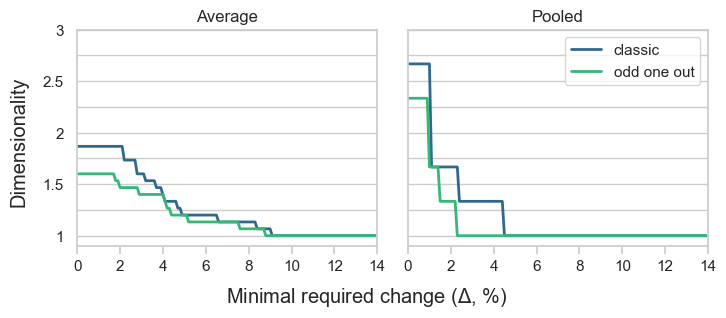

In [16]:
g = sns.relplot(data=dftoplot, 
            x='delta_percentage', y='dim', 
            hue='task', kind='line', 
            col='obs',
            palette=palette_task,
            estimator=np.mean,
            linewidth=2,
            #errorbar=('pi', 100),
            errorbar=None,
            # square panels drawn at about the size of the other two-panel figures of the paper
            height=3,
            facet_kws={'despine': False})

#for ax in g.axes.flatten():
#    ax.vlines(x=2, ymin=0, ymax=3, color='k', linestyle='--')

g.set(ylim=(0.90, 3), xlim=(0, 14))
#g.set(yticks=[1, 1.25, 1.5, 1.75, 2.0, 2.25, 2.5])
g.set_xlabels('')
g.set_ylabels('')
for obs, ax in g.axes_dict.items():
    ax.set_title(obs.capitalize())
    # horizontal lines every 0.25 in the grey of the panel border, labelled every other line
    ax.set_yticks([1, 1.25, 1.5, 1.75, 2, 2.25, 2.5, 2.75, 3])
    ax.set_yticklabels(['1', '', '1.5', '', '2', '', '2.5', '', '3'])
    ax.grid(axis='y', color='0.8')
    ax.set_xticks([0, 2, 4, 6, 8, 10, 12, 14])
    # the whitegrid style hides tick marks; show them in the grey of the panel border
    ax.tick_params(axis='x', bottom=True, color='0.8')
# inside the pooled panel, where the curves have dropped to one dimension,
# framed and without title as in the other figures
handles, labels = g.legend.legend_handles, [text.get_text() for text in g.legend.texts]
g.legend.remove()
g.axes_dict['pooled'].legend(handles, labels, loc='upper right', frameon=True)
#g.set_xlabels(r'Required percentage change for effect size criterion ($\Delta$) [%]')
# tight_layout ignores the figure level labels: leave a margin on the left for the
# y label, and hang the x label just below the tick labels of the panels
g.tight_layout(rect=(0.035, 0, 1, 1))
g.fig.supylabel('Dimensionality', x=0.015)
panels_bottom = min(ax.get_position().y0 for ax in g.axes.flat)
g.fig.supxlabel(r'Minimal required change ($\Delta$, %)', y=panels_bottom - 0.13, va='top')
g.savefig(f"../plots/criterion_sensitivity_analysis_embeddings_task_comparison_avg_and_pooled.pdf")

In [17]:
## Calculating difference 
df_pivoted = dftoplot.pivot_table(values='dim', index=['task', 'delta_percentage'], columns = 'obs').reset_index()
df_pivoted

obs,task,delta_percentage,average,pooled
0,classic,0.0,1.866667,2.666667
1,classic,0.1,1.866667,2.666667
2,classic,0.2,1.866667,2.666667
3,classic,0.3,1.866667,2.666667
4,classic,0.4,1.866667,2.666667
...,...,...,...,...
275,odd one out,13.5,1.000000,1.000000
276,odd one out,13.6,1.000000,1.000000
277,odd one out,13.7,1.000000,1.000000
278,odd one out,13.8,1.000000,1.000000


In [18]:
df_pivoted['dim_pooled_avg'] = df_pivoted['pooled'] - df_pivoted['average']
df_criteria_diff = df_pivoted.melt(id_vars = ['task','delta_percentage'], var_name='dim_diff', value_name='dim')
df_criteria_diff = df_criteria_diff[df_criteria_diff['dim_diff'] == 'dim_pooled_avg']
df_criteria_diff 

,task,delta_percentage,dim_diff,dim
560,classic,0.0,dim_pooled_avg,0.8
561,classic,0.1,dim_pooled_avg,0.8
562,classic,0.2,dim_pooled_avg,0.8
563,classic,0.3,dim_pooled_avg,0.8
564,classic,0.4,dim_pooled_avg,0.8
...,...,...,...,...
835,odd one out,13.5,dim_pooled_avg,0.0
836,odd one out,13.6,dim_pooled_avg,0.0
837,odd one out,13.7,dim_pooled_avg,0.0
838,odd one out,13.8,dim_pooled_avg,0.0


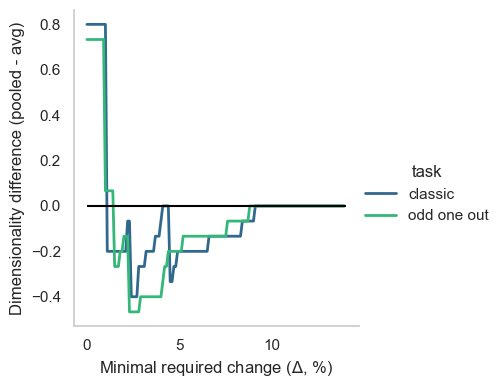

In [19]:
g = sns.relplot(data=df_criteria_diff, 
            x='delta_percentage', y='dim', 
            kind='line', 
            linewidth=2,
            hue='task',
            palette=palette_task,
            estimator=np.mean,
            errorbar=None,
            height=4)

#g.axes[0][0].vlines(x=2, ymin=-1, ymax=1, color='k', linestyle='--')
g.axes[0][0].hlines(y=0, xmin=0, xmax=14, color='k', linestyle='-')
    
#g.set(ylim=(-0.1, 1))
g.set_xlabels('')
g.set_ylabels('Dimensionality difference (pooled - avg)')
g.set_xlabels(r'Minimal required change ($\Delta$, %)')
g.savefig(f"../plots/criterion_sensitivity_analysis_embeddings_diff_pooled-avg.pdf")

In [20]:
# save csv with updated dimensionality and embedding
idx1 = (new_df['observer']!='pooled O1 - O5')
idx2 = (new_df['observer']=='pooled O1 - O5')

new_df[idx1].to_csv('../data/found-dimensionality-embeddings-aggregated-per-observer-nsplit-5-nrepeat-30-LogOdds.csv')
new_df[idx2].to_csv('../data/found-dimensionality-embeddings-pooled-observers-nsplit-5-nrepeat-30-LogOdds.csv')


In [21]:
# Retrieving numbers for delta =0, needs to match average dimensionality
df_pivoted[df_pivoted['delta_percentage']==0.0]

obs,task,delta_percentage,average,pooled,dim_pooled_avg
0,classic,0.0,1.866667,2.666667,0.800000
140,odd one out,0.0,1.600000,2.333333,0.733333


In [22]:
# From table 1
avg_classic = (1.6 + 2 + 2)/3
avg_classic

1.8666666666666665

In [23]:
avg_ooo = (1.8 + 1.4 + 1.6)/3
avg_ooo

1.6000000000000003

In [24]:
pooled_classic = (4 + 2 + 2)/3
pooled_classic

2.6666666666666665

In [25]:
pooled_ooo = (3 + 2 + 2)/3
pooled_ooo

2.3333333333333335